In [ ]:
import numpy as np
import pandas as pd
import random
from scipy.optimize import minimize, Bounds

# --- Benchmark Functions F1–F23 ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# --- Numerical Gradient ---
def numerical_gradient(func, x, eps=1e-8):
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x1 = np.copy(x)
        x2 = np.copy(x)
        x1[i] += eps
        x2[i] -= eps
        f1 = func(x1)
        f2 = func(x2)
        grad[i] = (f1 - f2) / (2 * eps) if np.isfinite(f1) and np.isfinite(f2) else 0
    return grad

# --- Interior Point Method (for initialization only) ---
def interior_point_init(func, x0, bounds=None):
    try:
        res = minimize(
            fun=func,
            x0=x0,
            method='trust-constr',
            jac=lambda x: numerical_gradient(func, x),
            hess=lambda x: np.eye(len(x)),
            bounds=bounds,
            options={'verbose': 0}
        )
        return res.x
    except:
        return x0  # fallback

# --- Powell's Dog Leg with Chaos (main optimizer) ---
def powells_dog_leg_with_chaos(func, grad_func, x0, trust_radius=1.0, tol=1e-6, max_iter=100, chaotic_prob=0.1):
    x = x0.copy()
    for _ in range(max_iter):
        grad = grad_func(x)
        if np.linalg.norm(grad) < tol:
            break
        hess = np.eye(len(x))
        newton_step = -np.linalg.solve(hess, grad)
        cauchy_point = -trust_radius * grad / np.linalg.norm(grad)

        if np.linalg.norm(newton_step) <= trust_radius:
            p = newton_step
        elif np.linalg.norm(cauchy_point) >= trust_radius:
            p = cauchy_point
        else:
            u = cauchy_point - newton_step
            a = np.dot(u, u)
            b = 2 * np.dot(u, newton_step)
            c = np.dot(newton_step, newton_step) - trust_radius**2
            discr = b**2 - 4 * a * c
            tau = (-b + np.sqrt(discr)) / (2 * a) if discr >= 0 else 1
            p = newton_step + tau * u

        if random.random() < chaotic_prob:
            p += (np.random.rand(len(x)) - 0.5) * 0.1

        alpha = 1.0
        while func(x + alpha * p) > func(x) + 1e-4 * alpha * np.dot(grad, p):
            alpha *= 0.5
            if alpha < 1e-6:
                break

        x = x + alpha * p
    return x

# --- Run Benchmark with IP init + Dog Leg ---
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    for _ in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        bounds = Bounds(low * np.ones(dim), high * np.ones(dim))
        x_init = interior_point_init(func, x0, bounds)
        result = powells_dog_leg_with_chaos(func, lambda x: numerical_gradient(func, x), x_init)
        val = func(result)
        results.append(val if np.isfinite(val) else np.nan)
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results)
    }

# --- Run All Benchmarks ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Run & Save ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)
results.to_excel('Benchmark_IP-C-PDL.xlsx')
print("\n✅ Results saved to Benchmark_IP-C-PDL.xlsx")

Running F01 (dim=30)...
Running F02 (dim=30)...
Running F03 (dim=30)...
Running F04 (dim=30)...
Running F05 (dim=30)...
Running F06 (dim=30)...
Running F07 (dim=30)...
Running F08 (dim=30)...
Running F09 (dim=30)...
Running F10 (dim=30)...
Running F11 (dim=30)...
Running F12 (dim=30)...
Running F13 (dim=30)...
Running F14 (dim=30)...
Running F15 (dim=30)...
Running F16 (dim=2)...
Running F17 (dim=2)...
Running F18 (dim=2)...
Running F19 (dim=2)...
Running F20 (dim=2)...
Running F21 (dim=2)...
Running F22 (dim=2)...
Running F23 (dim=2)...

--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       2.236125e-21  1.625463e-19  1.252760e-19  6.520139e-19  1.512047e-19
F02       1.341215e-01  3.847036e+01  1.906813e+01  2.675795e+02  5.593497e+01
F03       5.263194e+02  9.033014e+02  9.347408e+02  1.189940e+03  1.602825e+02
F04       1.275322e+01  1.384960e+

Running F01 (dim=30)...


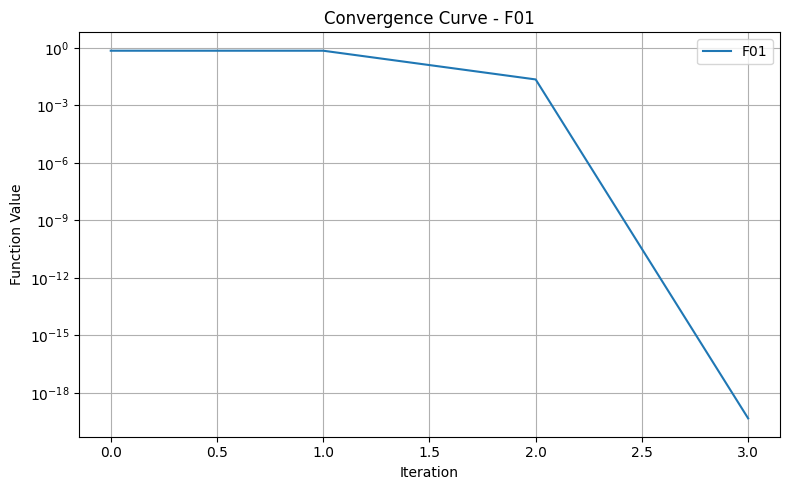

Running F02 (dim=30)...


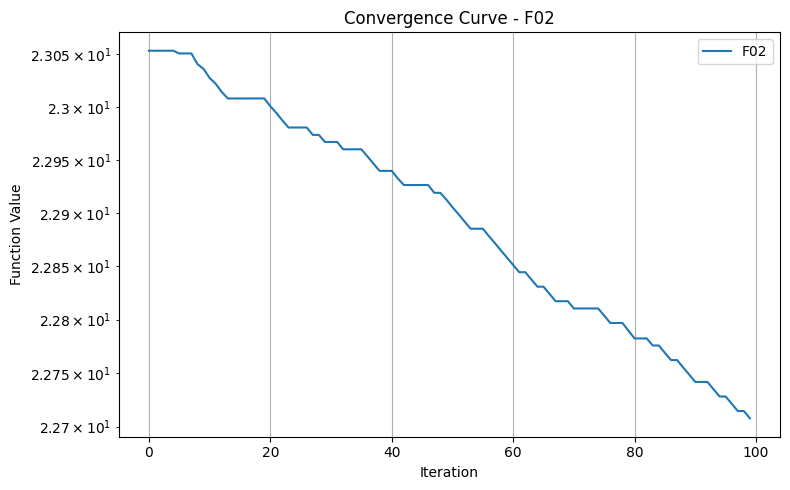

Running F03 (dim=30)...


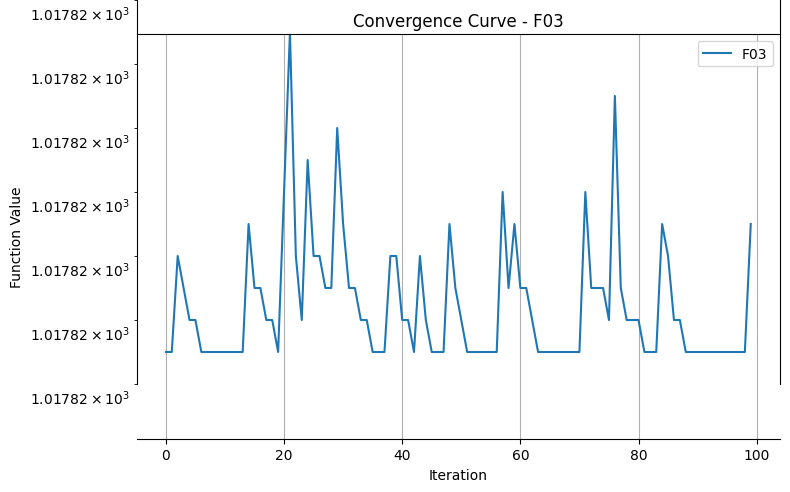

Running F04 (dim=30)...


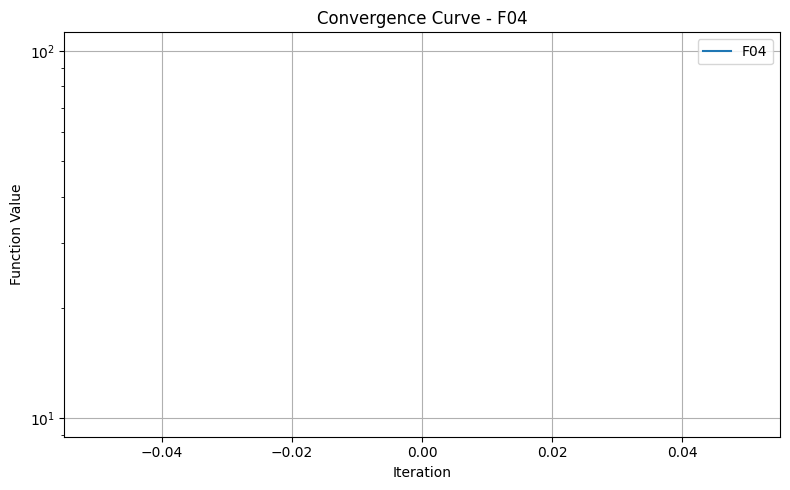

Running F05 (dim=30)...


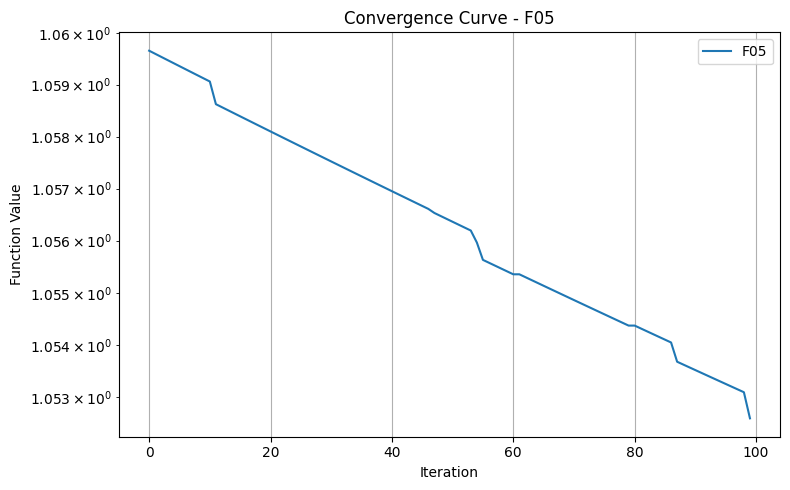

Running F06 (dim=30)...


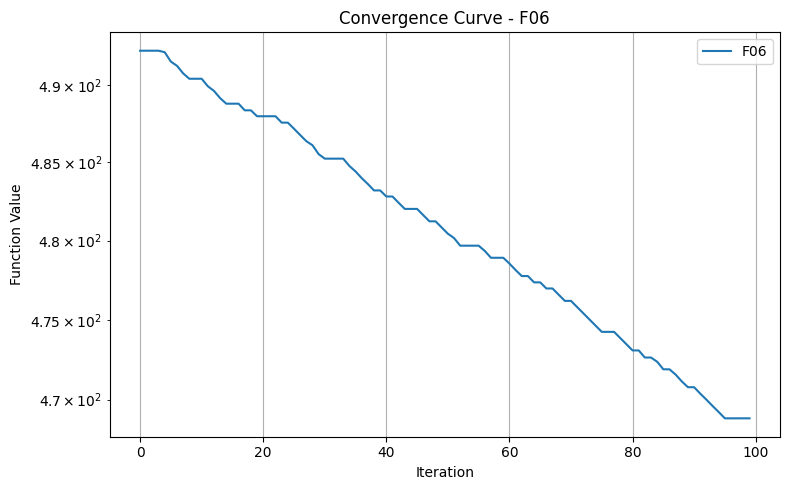

Running F07 (dim=30)...


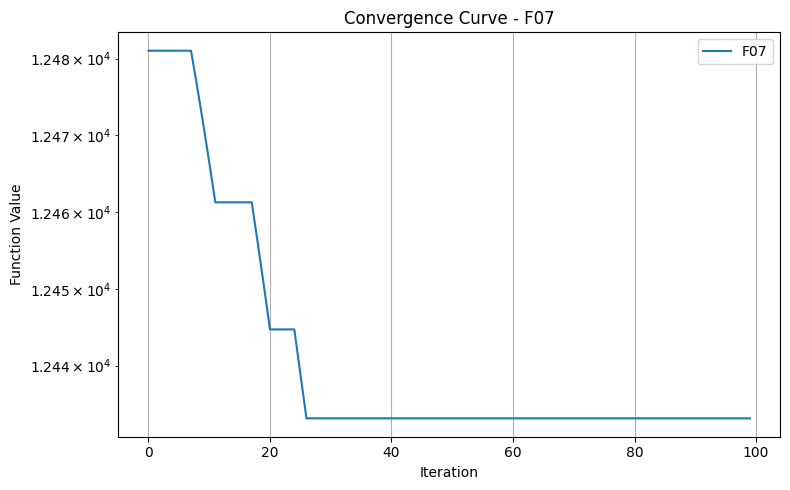

Running F08 (dim=30)...


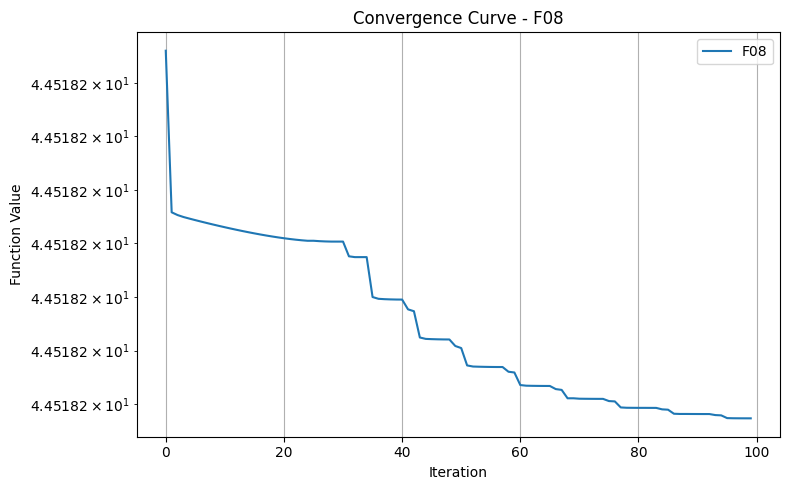

Running F09 (dim=30)...


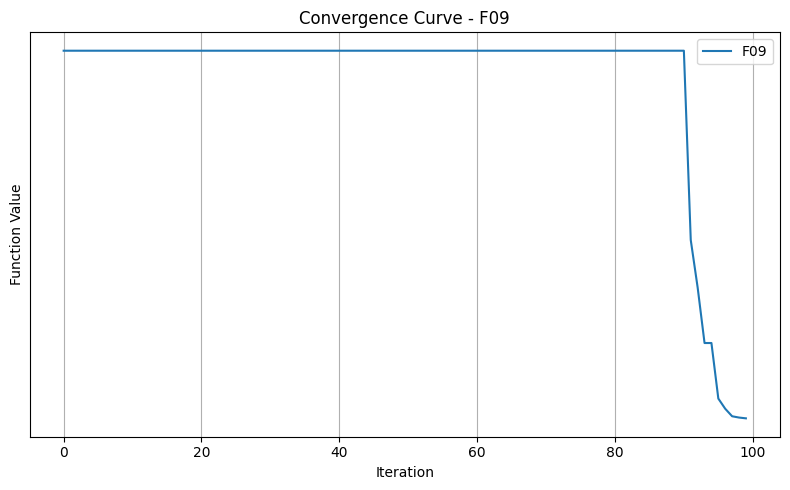

Running F10 (dim=30)...


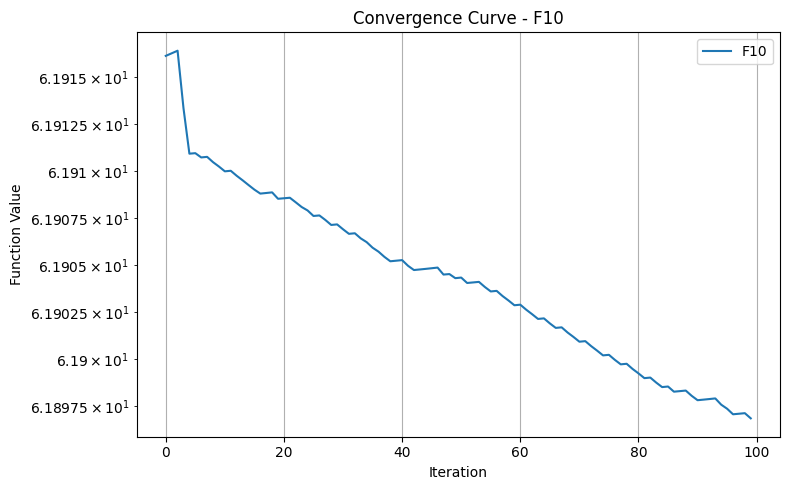

Running F11 (dim=30)...


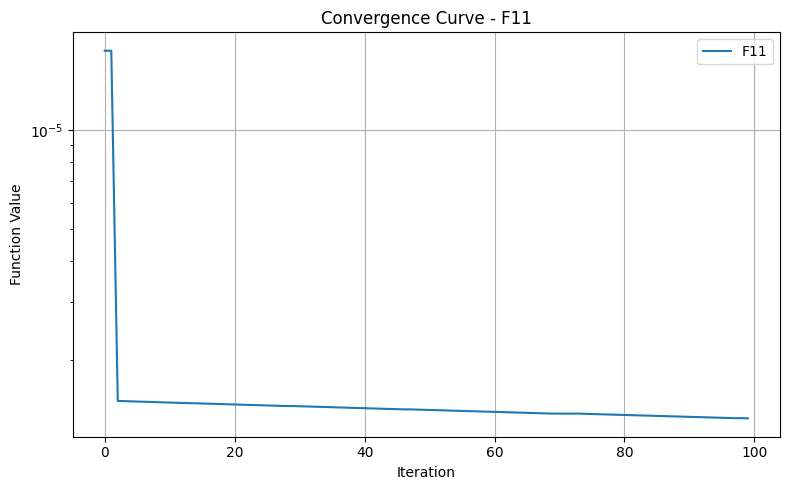

Running F12 (dim=30)...


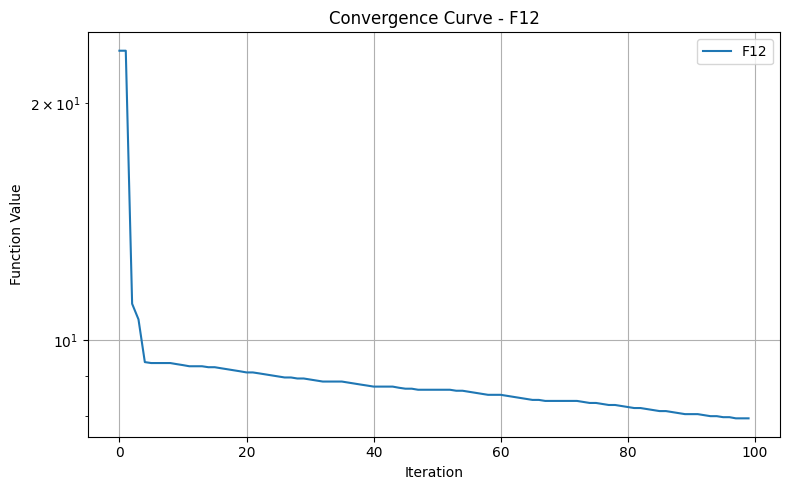

Running F13 (dim=30)...


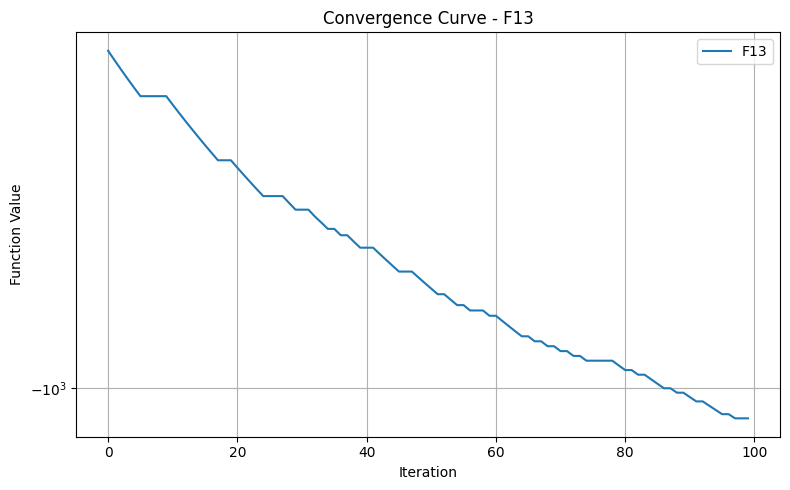

Running F14 (dim=30)...


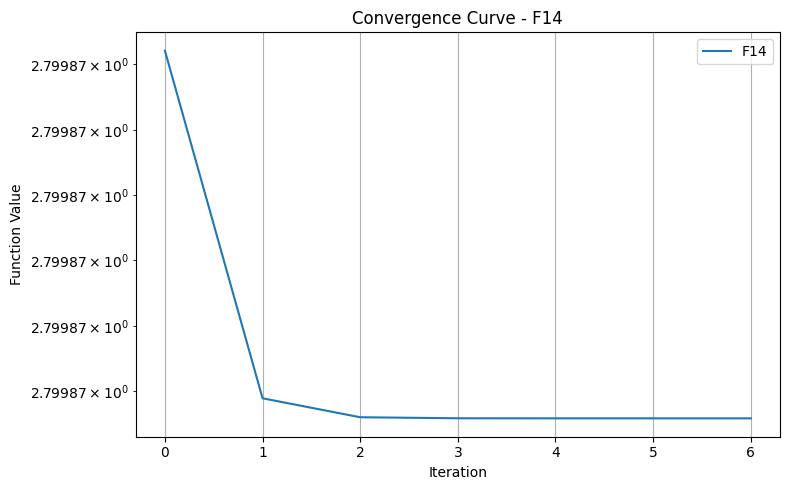

Running F15 (dim=30)...


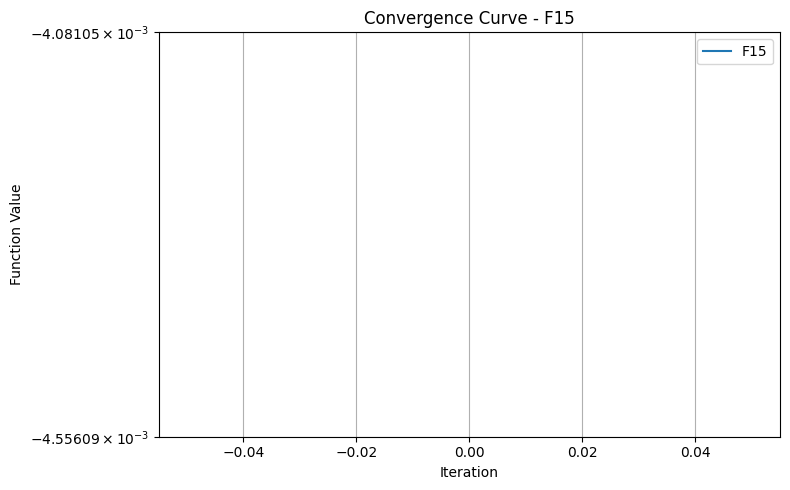

Running F16 (dim=2)...


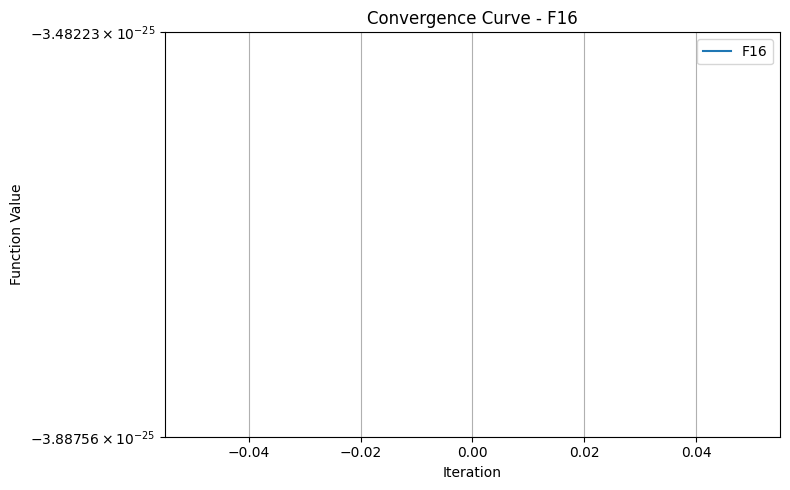

Running F17 (dim=2)...


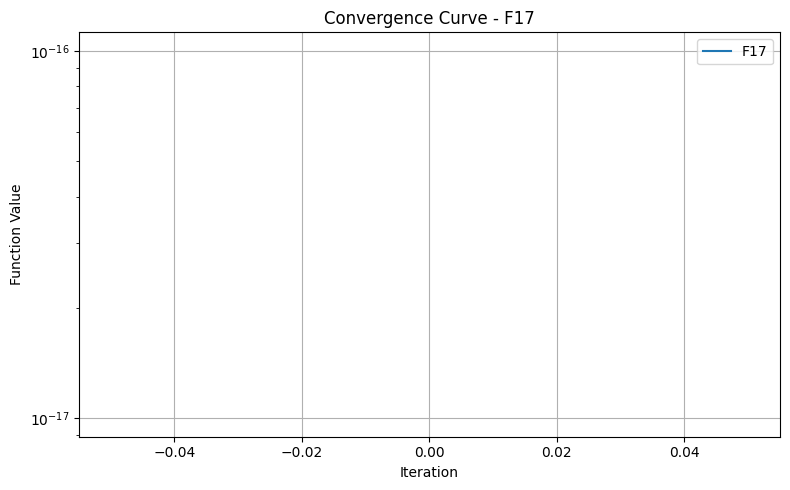

Running F18 (dim=2)...


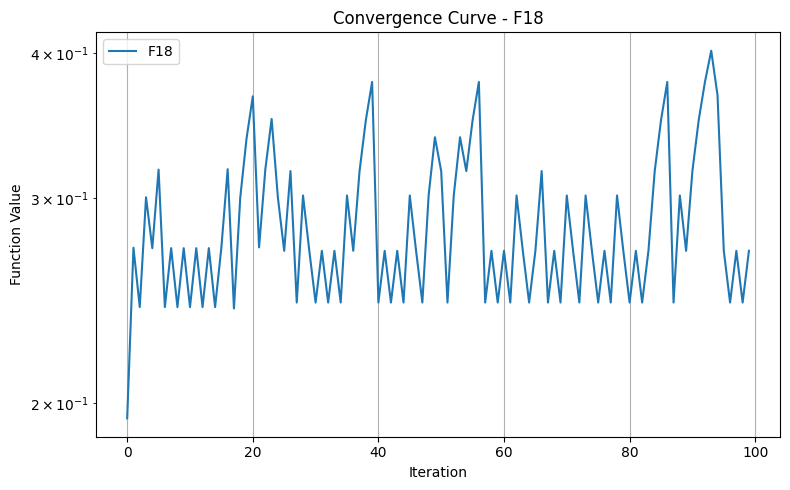

Running F19 (dim=2)...


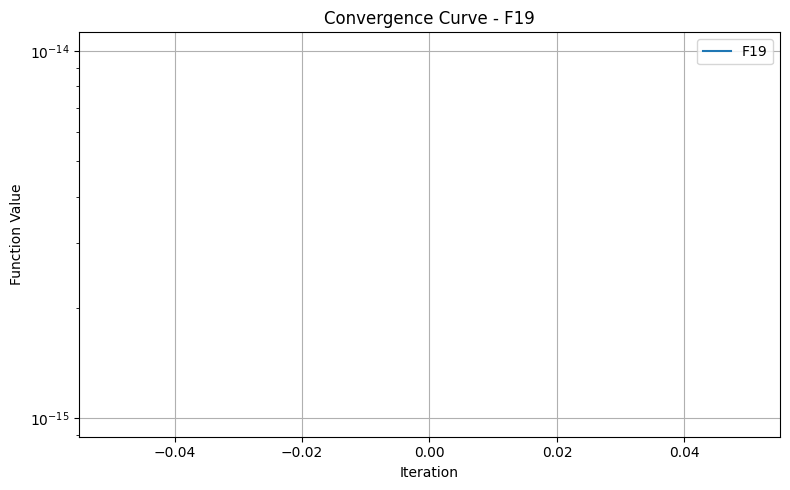

Running F20 (dim=2)...


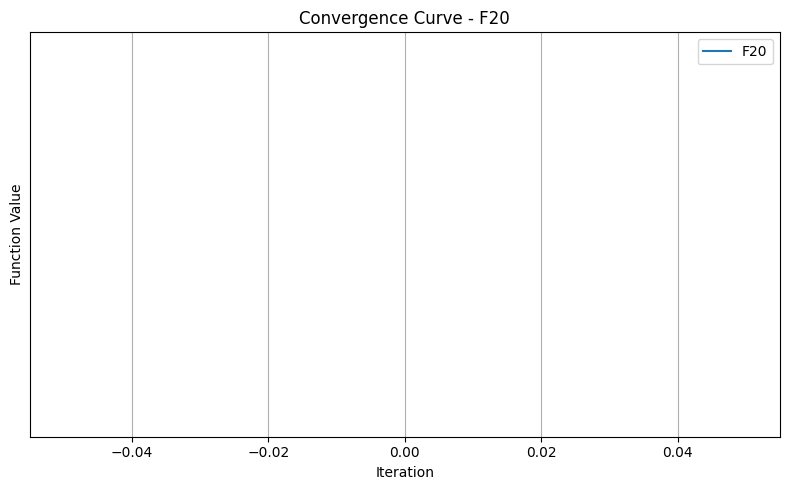

Running F21 (dim=2)...


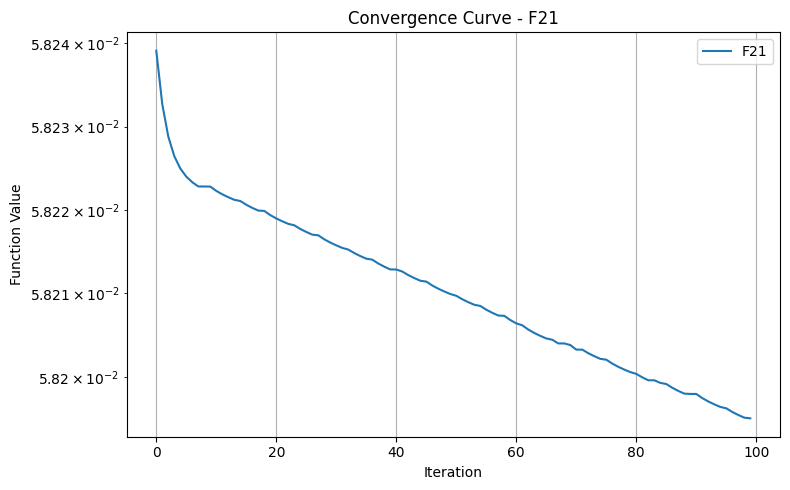

Running F22 (dim=2)...


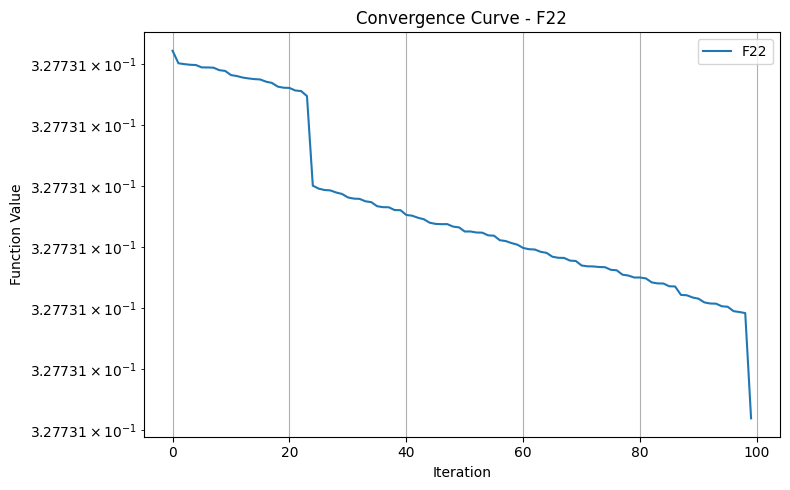

Running F23 (dim=2)...


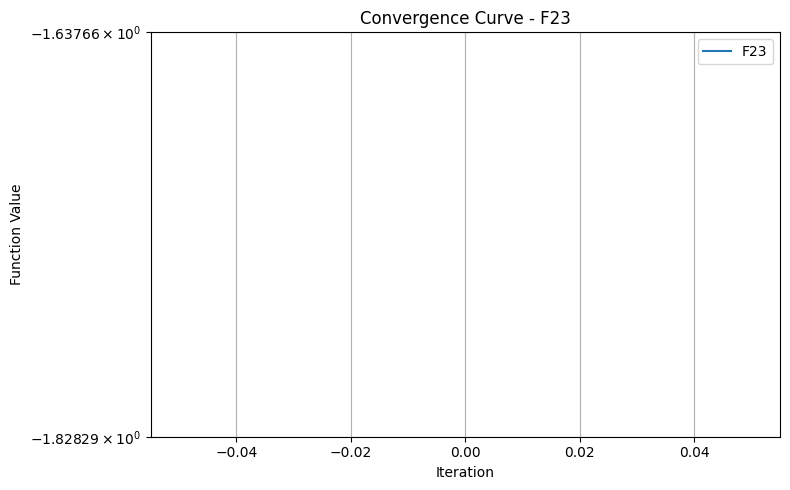


--- Benchmark Results ---
                  Best          Mean        Median         Worst           STD
Function                                                                      
F01       6.479327e-22  1.883247e-19  8.515059e-20  7.995939e-19  2.171881e-19
F02       1.764969e+01  2.545112e+01  1.904692e+01  1.204301e+02  2.302192e+01
F03       5.959660e+02  8.886432e+02  8.636027e+02  1.412800e+03  1.689139e+02
F04       1.149225e+01  1.332663e+01  1.342014e+01  1.433979e+01  7.869242e-01
F05       1.052594e+00  1.068961e+00  1.068597e+00  1.086024e+00  9.573477e-03
F06       2.654396e+02  4.627647e+02  4.714717e+02  6.780063e+02  1.022972e+02
F07       1.215701e+04  1.232953e+04  1.233030e+04  1.244042e+04  6.344227e+01
F08       3.799436e+01  5.524626e+01  5.786014e+01  7.204623e+01  9.142498e+00
F09      -6.427791e+00 -3.698086e+00 -3.385703e+00 -1.503516e+00  1.339708e+00
F10       1.073433e-01  3.816038e+01  3.420756e+01  8.892675e+01  3.035587e+01
F11       1.358595e-09  9

In [2]:
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
from scipy.optimize import minimize, Bounds

# --- Benchmark Functions (F1–F23) ---
def F1(x): return np.sum(x**2)
def F2(x): return np.sum(100 * (x[1:] - x[:-1]**2)**2 + (x[:-1] - 1)**2)
def F3(x): return np.sum(x**2 - 10 * np.cos(2 * np.pi * x) + 10)
def F4(x): return -20 * np.exp(-0.2*np.sqrt(np.mean(x**2))) - np.exp(np.mean(np.cos(2*np.pi*x))) + 20 + np.e
def F5(x): return np.sum(x**2)/4000 - np.prod(np.cos(x / np.sqrt(np.arange(1, len(x)+1)))) + 1
def F6(x): return np.sum(x**2) + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**2 + (np.sum(0.5 * np.arange(1, len(x)+1) * x))**4
def F7(x): return 418.9829 * len(x) - np.sum(x * np.sin(np.sqrt(np.abs(x))))
def F8(x): 
    w = 1 + (x - 1) / 4
    return np.sin(np.pi * w[0])**2 + np.sum((w[:-1] - 1)**2 * (1 + 10*np.sin(np.pi*w[:-1] + 1)**2)) + (w[-1]-1)**2 * (1 + np.sin(2*np.pi*w[-1])**2)
def F9(x): return -np.sum(np.sin(x) * np.sin(((np.arange(1, len(x)+1) * x**2) / np.pi))**20)
def F10(x): return x[0]**2 + 1e6 * np.sum(x[1:]**2)
def F11(x): return np.sum(np.abs(x)**(2 + 4*np.arange(len(x))/(len(x)-1)))
def F12(x): return np.sum([np.sum(x[:i])**2 for i in range(1, len(x)+1)])
def F13(x): return np.sum((x - 1)**2) - np.sum(x[:-1] * x[1:])
def F14(x): return 1 - np.cos(2*np.pi*np.sqrt(np.sum(x**2))) + 0.1*np.sqrt(np.sum(x**2))
def F15(x): return - (1 + np.cos(12*np.sqrt(np.sum(x**2)))) / (0.5*np.sum(x**2) + 2)
def F16(x): return -np.cos(x[0]) * np.cos(x[1]) * np.exp(-(x[0]-np.pi)**2 - (x[1]-np.pi)**2)
def F17(x): return (x[0] + 2*x[1] - 7)**2 + (2*x[0] + x[1] - 5)**2
def F18(x): return 100*np.sqrt(abs(x[1] - 0.01*x[0]**2)) + 0.01*abs(x[0] + 10)
def F19(x): return 0.26*(x[0]**2 + x[1]**2) - 0.48*x[0]*x[1]
def F20(x): return np.sin(x[0]+x[1]) + (x[0]-x[1])**2 - 1.5*x[0] + 2.5*x[1] + 1
def F21(x): return 0.5 + (np.sin(x[0]**2 - x[1]**2)**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F22(x): return 0.5 + (np.cos(np.sin(abs(x[0]**2 - x[1]**2)))**2 - 0.5)/(1 + 0.001*(x[0]**2 + x[1]**2))**2
def F23(x): 
    r = np.sqrt(x[0]**2 + x[1]**2)
    z = np.clip(abs(1 - r / np.pi), -50, 50)
    try:
        exp_term = np.exp(z)
    except:
        exp_term = 1e10
    return -abs(np.sin(x[0]) * np.cos(x[1]) * exp_term)

benchmark_functions = {
    f"F{str(i+1).zfill(2)}": f for i, f in enumerate([
        F1, F2, F3, F4, F5, F6, F7, F8, F9, F10, F11, F12, F13, F14, F15,
        F16, F17, F18, F19, F20, F21, F22, F23
    ])
}

# --- Numerical Gradient ---
def numerical_gradient(func, x, eps=1e-8):
    grad = np.zeros_like(x)
    for i in range(len(x)):
        x1 = np.copy(x)
        x2 = np.copy(x)
        x1[i] += eps
        x2[i] -= eps
        f1 = func(x1)
        f2 = func(x2)
        grad[i] = (f1 - f2) / (2 * eps) if np.isfinite(f1) and np.isfinite(f2) else 0
    return grad

# --- Interior Point Method (Initialization) ---
def interior_point_init(func, x0, bounds=None):
    try:
        res = minimize(
            fun=func,
            x0=x0,
            method='trust-constr',
            jac=lambda x: numerical_gradient(func, x),
            hess=lambda x: np.eye(len(x)),
            bounds=bounds,
            options={'verbose': 0}
        )
        return res.x
    except:
        return x0

# --- Powell's Dog Leg with Chaos + Convergence Tracking ---
def powells_dog_leg_with_chaos(func, grad_func, x0, trust_radius=1.0, tol=1e-6, max_iter=100, chaotic_prob=0.1):
    x = x0.copy()
    convergence_curve = []

    for _ in range(max_iter):
        fx = func(x)
        convergence_curve.append(fx)
        grad = grad_func(x)
        if np.linalg.norm(grad) < tol:
            break
        hess = np.eye(len(x))
        newton_step = -np.linalg.solve(hess, grad)
        cauchy_point = -trust_radius * grad / np.linalg.norm(grad)

        if np.linalg.norm(newton_step) <= trust_radius:
            p = newton_step
        elif np.linalg.norm(cauchy_point) >= trust_radius:
            p = cauchy_point
        else:
            u = cauchy_point - newton_step
            a = np.dot(u, u)
            b = 2 * np.dot(u, newton_step)
            c = np.dot(newton_step, newton_step) - trust_radius**2
            discr = b**2 - 4 * a * c
            tau = (-b + np.sqrt(discr)) / (2 * a) if discr >= 0 else 1
            p = newton_step + tau * u

        if random.random() < chaotic_prob:
            p += (np.random.rand(len(x)) - 0.5) * 0.1

        alpha = 1.0
        while func(x + alpha * p) > fx + 1e-4 * alpha * np.dot(grad, p):
            alpha *= 0.5
            if alpha < 1e-6:
                break

        x = x + alpha * p

    return x, convergence_curve

# --- Run Benchmark on Single Function ---
def run_benchmark(func, dim, runs=30, low=-10, high=10):
    results = []
    last_convergence = None
    for i in range(runs):
        x0 = np.random.uniform(low, high, size=dim)
        bounds = Bounds(low * np.ones(dim), high * np.ones(dim))
        x_init = interior_point_init(func, x0, bounds)
        x_opt, convergence = powells_dog_leg_with_chaos(func, lambda x: numerical_gradient(func, x), x_init)
        val = func(x_opt)
        results.append(val if np.isfinite(val) else np.nan)
        if i == runs - 1:
            last_convergence = convergence
    return {
        'Best': np.nanmin(results),
        'Mean': np.nanmean(results),
        'Median': np.nanmedian(results),
        'Worst': np.nanmax(results),
        'STD': np.nanstd(results),
        'Convergence': last_convergence
    }

# --- Run All Benchmarks with Plotting ---
def run_all_benchmarks(dim=30, runs=30):
    summary = []
    for name, func in benchmark_functions.items():
        d = 2 if name in ['F16','F17','F18','F19','F20','F21','F22','F23'] else dim
        print(f"Running {name} (dim={d})...")
        stats = run_benchmark(func, dim=d, runs=runs)
        convergence = stats.pop('Convergence')

        if convergence:
            plt.figure(figsize=(8, 5))
            plt.plot(convergence, label=name)
            if all(val > 0 for val in convergence):
                plt.yscale('log')
            else:
                plt.yscale('symlog')
            plt.xlabel('Iteration')
            plt.ylabel('Function Value')
            plt.title(f'Convergence Curve - {name}')
            plt.grid(True)
            plt.legend()
            plt.tight_layout()
            plt.show()

        stats['Function'] = name
        summary.append(stats)
    return pd.DataFrame(summary).set_index("Function")

# --- Execute All ---
results = run_all_benchmarks(dim=30, runs=30)
print("\n--- Benchmark Results ---")
print(results)

# Save Excel
results.to_excel('Benchmark_IP-C-PDL.xlsx')
print("\n✅ Results saved to Benchmark_IP-C-PDL.xlsx")